<a href="https://colab.research.google.com/github/CooL-Legend/CSCI544-DLM/blob/adi/notebooks/gsm8k/Verify_Batch_Processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"/></a>

# Batch Processing Verification: MEDAL & AB-MEDAL on GSM8K

This diagnostic notebook validates that **cooperative tree search batch processing works as intended for both MEDAL and AB-MEDAL** on GSM8K with `LLaDA-8B-Instruct`.

It references both base notebooks:
- [MEDAL_MCTS_Demo.ipynb](MEDAL_MCTS_Demo.ipynb) (base MEDAL notebook)
- [AB_MEDAL_MCTS_Colab.ipynb](AB_MEDAL_MCTS_Colab.ipynb) (base AB-MEDAL notebook)

---

## What This Notebook Checks
1. **Single Model Load**: Loads `LLaDA-8B-Instruct` in bfloat16 once and reuses it across both algorithm evaluations.
2. **Padding Probe Parity**: Confirms that right-padded batch tensors produce logits that match unpadded serial forwards on identical root and selected states.
3. **Full Tree & Parity Verification**: Compares complete search trees, visit counts, backed-up rewards ($Q$), Student-t GEN/CONT traversal decisions (AB-MEDAL), selected candidates, and completed answers between serial (`batch_size=1`) and batched (`batch_size=4`) runs with search budget $B = 256$ (Condition A).
4. **Throughput Speedup**: Measures empirical latency reduction and model invocation savings.


## 1. Verify GPU Hardware
Verify that a CUDA GPU supporting bfloat16 (recommended: L4 or A100 with >= 22 GiB VRAM) is active.

In [1]:
import torch

if not torch.cuda.is_available():
    raise RuntimeError("Select a CUDA GPU runtime in Colab (L4 or A100), then reconnect.")
gpu = torch.cuda.get_device_properties(0)
vram_gib = gpu.total_memory / (1024 ** 3)
print(f"GPU: {gpu.name} | Total VRAM: {vram_gib:.1f} GiB")
if vram_gib < 20:
    raise RuntimeError("This notebook uses unquantized BF16 weights. Choose an L4 or A100 runtime with >= 22 GB VRAM; 16 GB T4 is too small.")
if not torch.cuda.is_bf16_supported():
    raise RuntimeError("This GPU does not support bfloat16 inference.")
print("✓ GPU hardware verification passed.")

GPU: NVIDIA L4 | Total VRAM: 22.0 GiB
✓ GPU hardware verification passed.


## 2. Repository Setup
Clone or update the GitHub repository on branch `adi`. Supports private repository authentication via Colab Secrets or password prompt.

In [2]:
from pathlib import Path
import getpass
import os
import subprocess
import sys
import tempfile

REPOSITORY = "CooL-Legend/CSCI544-DLM"
BRANCH = "adi-batch-verification"
REPO_URL = f"https://github.com/{REPOSITORY}.git"
IN_COLAB = Path("/content").is_dir()
REPO_DIR = Path("/content/CSCI544-DLM") if IN_COLAB else next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "src/dlm_project").is_dir()
)

def run_git(args, token=None):
    env = {**os.environ, "GIT_TERMINAL_PROMPT": "0"}
    with tempfile.TemporaryDirectory() as tmp:
        if token:
            askpass = Path(tmp) / "askpass.py"
            askpass.write_text(
                "#!/usr/bin/env python3\nimport os, sys\n"
                "print('x-access-token' if 'username' in sys.argv[1].lower() else os.environ['COLAB_GH_TOKEN'])\n"
            )
            askpass.chmod(0o700)
            env.update(GIT_ASKPASS=str(askpass), COLAB_GH_TOKEN=token)
        return subprocess.run(["git", "-c", "credential.helper=", *args], env=env, capture_output=True, text=True)

def remote_git(args):
    result = run_git(args)
    if result.returncode:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
        if not token:
            token = getpass.getpass("GitHub token with read access to private repo CooL-Legend/CSCI544-DLM: ")
        try:
            result = run_git(args, token)
        finally:
            del token
    if result.returncode:
        raise RuntimeError(result.stderr.strip() or "GitHub clone/update failed.")

def ensure_checkout():
    def local_git(*args):
        return subprocess.check_output(["git", "-C", str(REPO_DIR), *args], text=True).strip()

    if REPO_DIR.exists():
        if not (REPO_DIR / ".git").is_dir():
            raise RuntimeError(f"{REPO_DIR} exists but is not a Git checkout.")
        fetch_specs = local_git("config", "--get-all", "remote.origin.fetch").splitlines()
        branch_ref = f"refs/heads/{BRANCH}:refs/remotes/origin/{BRANCH}"
        if not any(spec.lstrip("+") in (branch_ref, "refs/heads/*:refs/remotes/origin/*") for spec in fetch_specs):
            local_git("remote", "set-branches", "--add", "origin", BRANCH)
        remote_git(["-C", str(REPO_DIR), "fetch", "origin", branch_ref])
        exists = subprocess.run(["git", "-C", str(REPO_DIR), "show-ref", "--verify", "--quiet", f"refs/heads/{BRANCH}"]).returncode == 0
        if exists:
            local_git("switch", BRANCH)
        else:
            local_git("switch", "--create", BRANCH, "--track", f"origin/{BRANCH}")
        local_git("merge", "--ff-only", f"origin/{BRANCH}")
    else:
        remote_git(["clone", "--branch", BRANCH, "--single-branch", REPO_URL, str(REPO_DIR)])
    print(f"Code ready: {REPO_DIR} | branch: {BRANCH} | commit: {local_git('rev-parse', '--short', 'HEAD')}")

if IN_COLAB:
    ensure_checkout()
else:
    print(f"Using local repository checkout: {REPO_DIR}")

os.chdir(REPO_DIR)
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

Code ready: /content/CSCI544-DLM | branch: adi-batch-verification | commit: 192a59e


## 3. Install Dependencies
Install pinned LLaDA dependencies, editable package installation, and plotting tools.

In [3]:
import site
import subprocess
import sys

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(REPO_DIR / "requirements/llada-colab.txt")], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "-e", str(REPO_DIR)], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "matplotlib", "pandas"], check=True)

for pkg in [*site.getsitepackages(), site.getusersitepackages()]:
    site.addsitedir(pkg)
print("✓ Dependencies installed and package paths loaded.")

✓ Dependencies installed and package paths loaded.


## 4. Mount Google Drive & Configure Cache
Mount Google Drive for persistent caching of model weights and experimental artifacts.

In [4]:
from pathlib import Path
import os

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive/CSCI544-DLM")
else:
    DRIVE_ROOT = REPO_DIR / ".cache/batch_verification"

DRIVE_ROOT.mkdir(parents=True, exist_ok=True)
os.environ["HF_HUB_CACHE"] = str(DRIVE_ROOT / "cache/hub")
os.environ["HF_DATASETS_CACHE"] = str(DRIVE_ROOT / "cache/datasets")

OUTPUT_DIR = DRIVE_ROOT / "results/batch_verification"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Persistent Drive Root:", DRIVE_ROOT)
print("Verification Output Directory:", OUTPUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Persistent Drive Root: /content/drive/MyDrive/CSCI544-DLM
Verification Output Directory: /content/drive/MyDrive/CSCI544-DLM/results/batch_verification


## 5. Verification Controls & Configuration
Configure verification for a **batch of 4** with search budget **$B = 256$** (Condition A: depth 10, budget 256):
- `NUM_QUESTIONS = 4`: Evaluates 4 frozen GSM8K dev questions (forming a batch of 4).
- `BATCH_SIZES = [4]`: Validates bit-for-bit parity and speedup against serial baseline for batch size 4.
- `CONDITION = "A"`: Condition A search protocol ($B = 256$ NFEs budget, depth 10).

In [5]:
# Verification configuration: Batch of 4 with search budget B = 256 (Condition A)
NUM_QUESTIONS = 4  # 4 frozen dev questions to form a batch of 4
BATCH_SIZES = [4]  # Check against batch of 4
CONDITION = "A"    # Condition A: init_tokens=10, max_model_calls=256 (Budget B=256)

print(f"=== Verification Setup ===")
print(f"  Frozen Questions: {NUM_QUESTIONS}")
print(f"  Batch Sizes to Test: {BATCH_SIZES}")
print(f"  Condition: {CONDITION} (depth 10, budget B=256)")

=== Verification Setup ===
  Frozen Questions: 4
  Batch Sizes to Test: [4]
  Condition: A (depth 10, budget B=256)


## 6. Cache & Load LLaDA-8B-Instruct (Shared Once)
Load the pinned `LLaDA-8B-Instruct` model and tokenizer on CUDA in bfloat16, and prepare evaluation prompts.

In [6]:
import shutil
from dlm_project.models.profiles import get_profile
from dlm_project.tasks.gsm8k import ab_development as dev

base_ctx = dev.context(stage="dev", condition=CONDITION, indices=tuple(range(NUM_QUESTIONS)))
profile = get_profile("llada")
model_name = profile["repo_id"].split("/")[-1]
drive_model_dir = DRIVE_ROOT / "models" / model_name
runtime_model_dir = Path("/content/models") / model_name

if IN_COLAB and drive_model_dir.is_dir() and not (runtime_model_dir / "config.json").is_file():
    print(f"Copying model from Google Drive to local fast NVMe: {runtime_model_dir}...")
    shutil.copytree(drive_model_dir, runtime_model_dir)

MODEL_PATH = str(runtime_model_dir if runtime_model_dir.is_dir() else (drive_model_dir if drive_model_dir.is_dir() else profile["repo_id"]))
print("Using model location:", MODEL_PATH)

wrapper = dev.load_model(base_ctx, model_path=MODEL_PATH, device="cuda", local_files_only=Path(MODEL_PATH).is_dir())
prepared = dev.prepare(wrapper, base_ctx)

print(f"✓ Model loaded: {wrapper.identity['family']} ({wrapper.identity['repo_id']})")
print(f"✓ Prepared {len(prepared)} frozen development prompts.")

print("Running initial warm-up...")
warmup_info = dev.warmup(wrapper, prepared, base_ctx, batch_size=max(BATCH_SIZES))
print(f"✓ Warm-up completed in {warmup_info['seconds']:.3f}s across batch size {max(BATCH_SIZES)}.")

Using model location: /content/models/LLaDA-8B-Instruct


Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


Loading checkpoint shards:   0%|          | 0/6 [00:00<?, ?it/s]

✓ Model loaded: llada (GSAI-ML/LLaDA-8B-Instruct)
✓ Prepared 4 frozen development prompts.
Running initial warm-up...
✓ Warm-up completed in 1.053s across batch size 4.


## 7. Verify MEDAL Batch Processing
Runs serial baseline (`batch_size=1`), padding probes, and batched execution (`batch_size=4`) for **MEDAL** (`CooperativeMEDALSearch`) with budget $B = 256$.
Asserts 100% bit-for-bit parity on all discrete properties and numerical tolerances.

In [7]:
from scripts.verify_batch_processing import verify_method_batching

medal_results = verify_method_batching(
    wrapper,
    method="medal",
    prepared=prepared,
    base_ctx=base_ctx,
    output_dir=OUTPUT_DIR,
    batch_sizes=BATCH_SIZES,
)


VERIFYING BATCH PROCESSING: MEDAL
Condition: A | Depth: 10 | Budget: 256
Questions: 4 | Batch Sizes to Test: [4]

[1/3] Running Serial Baseline (batch_size=1) for medal...
  ✓ Serial completed in 573.96s | Status: completed
  ✓ Search NFEs: 1024 | Completion NFEs: 999 | Invocations: 2023

[2/3] Probing Padding Consistency (batch_size=4) for medal...
  Padding Probe Result: ✓ PASSED (100% bit-for-bit identical)

[3/3] Running Full Batched Search & Completion (batch_size=4) for medal...
  ✓ Batched execution finished in 424.81s (Speedup: 1.35x)
  ✓ Model Invocations reduced from 2023 down to 507 (4.0x fewer forward calls)
  ✓ Search NFEs conserved: 1024 == 1024 (True)
  ✓ Answer Agreement: 4/4 (100.0%) | Serial Acc: 0.25 vs Batched Acc: 0.25
  ✓ Parity Verdict: ✓ PASSED (Bit-for-bit identical)


## 8. Verify AB-MEDAL Batch Processing
Runs serial baseline (`batch_size=1`), padding probes, and batched execution (`batch_size=4`) for **AB-MEDAL** (`ABMEDALSearch`) with budget $B = 256$.
Asserts 100% bit-for-bit parity on all discrete properties, Student-t Bayesian GEN/CONT decisions, and completions.

In [8]:
ab_medal_results = verify_method_batching(
    wrapper,
    method="ab_medal",
    prepared=prepared,
    base_ctx=base_ctx,
    output_dir=OUTPUT_DIR,
    batch_sizes=BATCH_SIZES,
)


VERIFYING BATCH PROCESSING: AB_MEDAL
Condition: A | Depth: 10 | Budget: 256
Questions: 4 | Batch Sizes to Test: [4]

[1/3] Running Serial Baseline (batch_size=1) for ab_medal...
  ✓ Serial completed in 570.66s | Status: completed
  ✓ Search NFEs: 1024 | Completion NFEs: 1002 | Invocations: 2026

[2/3] Probing Padding Consistency (batch_size=4) for ab_medal...
  Padding Probe Result: ✓ PASSED (100% bit-for-bit identical)

[3/3] Running Full Batched Search & Completion (batch_size=4) for ab_medal...
  ✓ Batched execution finished in 426.28s (Speedup: 1.34x)
  ✓ Model Invocations reduced from 2026 down to 507 (4.0x fewer forward calls)
  ✓ Search NFEs conserved: 1024 == 1024 (True)
  ✓ Answer Agreement: 4/4 (100.0%) | Serial Acc: 0.75 vs Batched Acc: 0.75
  ✓ Parity Verdict: ✓ PASSED (Bit-for-bit identical)


## 9. Comprehensive Summary Dashboard & Visualizations
Compile and display side-by-side verification table and throughput comparison plots.

PARITY VERIFICATION TABLE


| Method | Batch Size | Padding Parity | Full Tree Parity | Serial Wall Time | Batched Wall Time | Speedup | Status |
|---|---|---|---|---|---|---|---|
| **MEDAL** | 4 | PASS | PASS | 573.96s | 424.81s | **1.35x** | ✓ VERIFIED |
| **AB_MEDAL** | 4 | PASS | PASS | 570.66s | 426.28s | **1.34x** | ✓ VERIFIED |

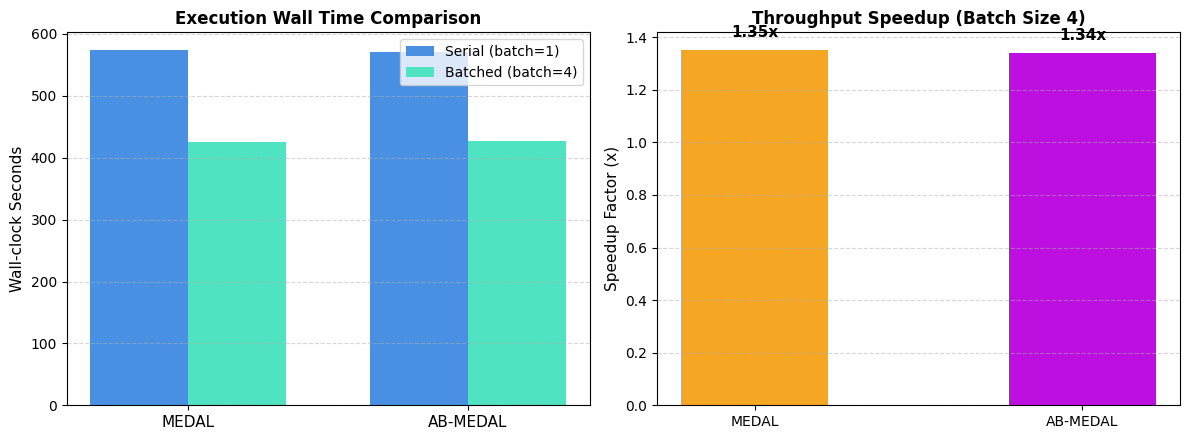

✓ VERIFICATION COMPLETE: ALL BATCH PROCESSING CHECKS PASSED FOR BOTH METHODS!
  Both MEDAL and AB-MEDAL cooperative batching produce 100% bit-for-bit identical results.


In [9]:
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scripts.verify_batch_processing import format_summary_table

all_results = {"medal": medal_results, "ab_medal": ab_medal_results}
summary_table = format_summary_table(all_results)

print("=" * 80)
print("PARITY VERIFICATION TABLE")
print("=" * 80)
display(Markdown(summary_table))

# Visualizations
target_batch = 4 if 4 in BATCH_SIZES else BATCH_SIZES[0]
methods = ["MEDAL", "AB-MEDAL"]
serial_times = [medal_results["serial"]["wall_seconds"], ab_medal_results["serial"]["wall_seconds"]]
batch_times = [medal_results["batches"][str(target_batch)]["wall_seconds"], ab_medal_results["batches"][str(target_batch)]["wall_seconds"]]
speedups = [medal_results["batches"][str(target_batch)]["speedup_over_serial"], ab_medal_results["batches"][str(target_batch)]["speedup_over_serial"]]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

x = [0, 1]
width = 0.35
ax1.bar([i - width/2 for i in x], serial_times, width, label="Serial (batch=1)", color="#4A90E2")
ax1.bar([i + width/2 for i in x], batch_times, width, label=f"Batched (batch={target_batch})", color="#50E3C2")
ax1.set_ylabel("Wall-clock Seconds", fontsize=11)
ax1.set_title("Execution Wall Time Comparison", fontsize=12, fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels(methods, fontsize=11)
ax1.legend(fontsize=10)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

bars = ax2.bar(methods, speedups, color=["#F5A623", "#BD10E0"], width=0.45)
ax2.set_ylabel("Speedup Factor (x)", fontsize=11)
ax2.set_title(f"Throughput Speedup (Batch Size {target_batch})", fontsize=12, fontweight="bold")
ax2.grid(axis='y', linestyle='--', alpha=0.5)
for bar, v in zip(bars, speedups):
    ax2.text(bar.get_x() + bar.get_width()/2, v + 0.05, f"{v:.2f}x", ha='center', fontweight='bold', fontsize=11)

plt.tight_layout()
plot_path = OUTPUT_DIR / "batch_verification_dashboard.png"
plt.savefig(plot_path, dpi=150)
plt.show()

all_passed = medal_results["all_passed"] and ab_medal_results["all_passed"]
print("=" * 80)
if all_passed:
    print("✓ VERIFICATION COMPLETE: ALL BATCH PROCESSING CHECKS PASSED FOR BOTH METHODS!")
    print("  Both MEDAL and AB-MEDAL cooperative batching produce 100% bit-for-bit identical results.")
else:
    print("✗ VERIFICATION FAILED: Check differences in the table above.")
print("=" * 80)